# 6.3 — Traditional Lexical Classification: Final TF-IDF Methodology

## Purpose

This notebook rebuilds the traditional lexical part of the Research Commons Māori-origin classification study as a **controlled, reproducible, interpretable experiment**.

It does **not** use or inspect any LLM/embedding predictions, confidence values, or generated reasons. The existing `classification_label` field is used only as:

1. the supervised target on the **training split**, and
2. the **reference label** for evaluation on the untouched held-out test split.

The notebook is outcome-neutral: the objective is not to make TF-IDF fail or succeed, but to determine **what lexical methods can identify, what they learn, and under which lexical conditions they agree or disagree with the reference labels**.

### Research questions addressed

- **RQ-T1 — Explicit keyword baseline:** How effectively can a fixed, transparent Māori-research lexicon identify records relative to the reference labels?
- **RQ-T2 — Learned lexical representation:** How effectively can TF-IDF + logistic regression learn the distinction from repository metadata?
- **RQ-T3 — Phrase features and imbalance:** What changes when phrase features and class weighting are varied independently?
- **RQ-T4 — Global interpretability:** Which learned words/phrases push predictions toward Māori-origin or non-Māori-origin?
- **RQ-T5 — Local interpretability:** Which words/phrases contribute most strongly to an individual TF-IDF prediction?
- **RQ-T6 — Lexical challenge conditions:** How does performance differ when Māori lexical evidence is explicit, incidental, weak/implicit, or embedded in broader New Zealand/Pacific/Indigenous vocabulary?
- **RQ-T7 — Probability reliability:** How well calibrated are TF-IDF model probabilities when calibration is learned only from training data?

### Primary lexical input

The main analysis uses **title + subjects + abstract**. These are the content-bearing metadata fields most directly related to the record's topic. Author names and publication year are deliberately excluded from the main lexical model so that the classifier is not rewarded for learning researcher identity or temporal shortcuts.

## 0. Install dependencies

In [1]:
!pip -q install datasets huggingface_hub scikit-learn pandas numpy matplotlib joblib pyarrow

## 1. Imports, reproducibility, and output directory

In [2]:
import os
import re
import json
import math
import random
import warnings
import unicodedata
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from datasets import load_dataset, Dataset
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix,
    brier_score_loss,
    precision_recall_curve,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DATASET_ID = "dinushiTJ/nz_research_commons_classification"
LABEL_COL = "classification_label"
ID_COL = "record_id_hash"
TEXT_FIELDS = ["title", "subjects", "abstract"]

# Fixed TF-IDF parameters used across all controlled ablations.
MAX_FEATURES = 10_000
MIN_DF = 2
LR_C = 1.0
LR_SOLVER = "liblinear"
LR_MAX_ITER = 2000

# Bootstrap replicates. 2000 is suitable for the final paper run;
# reduce temporarily if you only want a quick development run.
BOOTSTRAP_N = 2000

# The final interpretable model is pre-specified by methodology, not selected
# after seeing test results: phrase features + class weighting.
FINAL_CONFIG_NAME = "phrases_1to3_balanced"

OUTPUT_DIR = Path("/content/tfidf_traditional_outputs") if Path("/content").exists() else Path("./tfidf_traditional_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset:", DATASET_ID)
print("Primary text fields:", TEXT_FIELDS)
print("Outputs:", OUTPUT_DIR.resolve())

Dataset: dinushiTJ/nz_research_commons_classification
Primary text fields: ['title', 'subjects', 'abstract']
Outputs: /content/tfidf_traditional_outputs


## 2. Load the fixed train/test dataset

The repository already contains the fixed study split. This notebook **does not create a new train/test split**.

Expected counts from the existing experiment are:

- train: 13,271 records
- test: 3,318 records
- train Māori-origin: 1,469
- train non-Māori-origin: 11,802
- test Māori-origin: 367
- test non-Māori-origin: 2,951

The checks below warn if the source dataset has changed.

In [3]:
dataset = load_dataset(DATASET_ID)
print(dataset)

assert "train" in dataset and "test" in dataset, "Expected fixed train and test splits."
assert LABEL_COL in dataset["train"].column_names
assert LABEL_COL in dataset["test"].column_names

train_df = dataset["train"].to_pandas().copy()
test_df = dataset["test"].to_pandas().copy()

print("Train rows:", len(train_df))
print("Test rows:", len(test_df))
print("Columns:", train_df.columns.tolist())

README.md:   0%|          | 0.00/1.12k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 83.2MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/13271 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3318 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['title', 'authors', 'subjects', 'abstract', 'text', 'record_id_hash', 'prompt', 'token_count', 'classification_label', 'classification_reason', 'year', 'classification_confidence', 'embedding_text', 'embedding_token_count', 'conversations'],
        num_rows: 13271
    })
    test: Dataset({
        features: ['title', 'authors', 'subjects', 'abstract', 'text', 'record_id_hash', 'prompt', 'token_count', 'classification_label', 'classification_reason', 'year', 'classification_confidence', 'embedding_text', 'embedding_token_count', 'conversations'],
        num_rows: 3318
    })
})
Train rows: 13271
Test rows: 3318
Columns: ['title', 'authors', 'subjects', 'abstract', 'text', 'record_id_hash', 'prompt', 'token_count', 'classification_label', 'classification_reason', 'year', 'classification_confidence', 'embedding_text', 'embedding_token_count', 'conversations']


In [7]:
# from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, f1_score

# # ClassLabel feature
# class_label = dataset["test"].features["classification_label"]

# # Ground truth IDs
# true_labels_id = dataset["test"]["classification_label"]

# # Ground truth strings
# true_labels = [
#     class_label.int2str(label_id)
#     for label_id in true_labels_id
# ]

# # Predicted strings using the keyword-rule baseline
# pred_labels = test_analysis["keyword_prediction"].map(decode_label)

# # Predicted IDs
# predicted_labels_id = [
#     class_label.str2int(label)
#     for label in pred_labels
# ]

# print(f"Unique true labels: {set(true_labels)}")
# print(f"Unique true labels (IDs): {set(true_labels_id)}")

# print(f"Unique predicted labels: {set(pred_labels)}")
# print(f"Unique predicted labels (IDs): {set(predicted_labels_id)}")

## 3. Decode the reference labels safely

The Hugging Face feature is a `ClassLabel` in the original dataset (`maori_origin = 0`, `non_maori_origin = 1`).

For this notebook we create an explicit binary analysis target:

- `y = 1` → `maori_origin`
- `y = 0` → `non_maori_origin`

This avoids the sign confusion that can occur when interpreting logistic-regression coefficients.

In [8]:
label_feature = dataset["train"].features[LABEL_COL]


def decode_label(value):
    # Hugging Face ClassLabel -> text
    if hasattr(label_feature, "int2str") and not isinstance(value, str):
        return label_feature.int2str(int(value))
    value = str(value)
    if value in {"0", "maori_origin"}:
        return "maori_origin"
    if value in {"1", "non_maori_origin"}:
        return "non_maori_origin"
    raise ValueError(f"Unexpected label value: {value!r}")

for df in (train_df, test_df):
    df["reference_label"] = df[LABEL_COL].map(decode_label)
    df["y"] = (df["reference_label"] == "maori_origin").astype(int)

print("Train reference counts:")
print(train_df["reference_label"].value_counts())
print("\nTest reference counts:")
print(test_df["reference_label"].value_counts())

expected = {
    "train_total": 13271,
    "test_total": 3318,
    "train_maori": 1469,
    "train_non_maori": 11802,
    "test_maori": 367,
    "test_non_maori": 2951,
}
observed = {
    "train_total": len(train_df),
    "test_total": len(test_df),
    "train_maori": int(train_df["y"].sum()),
    "train_non_maori": int((1 - train_df["y"]).sum()),
    "test_maori": int(test_df["y"].sum()),
    "test_non_maori": int((1 - test_df["y"]).sum()),
}

for key, exp in expected.items():
    if observed[key] != exp:
        warnings.warn(f"{key}: expected {exp}, observed {observed[key]}. Dataset may have changed.")

observed

Train reference counts:
reference_label
non_maori_origin    11802
maori_origin         1469
Name: count, dtype: int64

Test reference counts:
reference_label
non_maori_origin    2951
maori_origin         367
Name: count, dtype: int64


{'train_total': 13271,
 'test_total': 3318,
 'train_maori': 1469,
 'train_non_maori': 11802,
 'test_maori': 367,
 'test_non_maori': 2951}

## 4. Build the lexical input

Only `title`, `subjects`, and `abstract` are concatenated. The original generated `classification_reason` and `classification_confidence` fields are **not used anywhere in this notebook**.

In [9]:
def clean_value(value):
    if value is None:
        return ""
    if isinstance(value, (list, tuple, set, np.ndarray)):
        return " ; ".join(str(x) for x in value if x is not None)
    try:
        if pd.isna(value):
            return ""
    except Exception:
        pass
    return str(value)


def build_lexical_text(row, fields=TEXT_FIELDS):
    parts = [clean_value(row.get(field, "")) for field in fields]
    return "\n".join(part.strip() for part in parts if part.strip())

train_df["lexical_text"] = train_df.apply(build_lexical_text, axis=1)
test_df["lexical_text"] = test_df.apply(build_lexical_text, axis=1)

analysis_columns = [c for c in [ID_COL, "title", "subjects", "abstract", "reference_label", "y", "lexical_text"] if c in train_df.columns]
train_analysis = train_df[analysis_columns].copy()
test_analysis = test_df[analysis_columns].copy()

print(train_analysis[["title", "subjects", "abstract", "reference_label"]].head(3).to_string(index=False))

                                                                                    title   subjects                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                    

# Part A — Transparent keyword-rule baseline

## 5. Pre-specified Māori-research lexicon

This baseline intentionally asks a simple question: **what happens if retrieval is driven by explicit Māori-related lexical cues?**

The lexicon is organized around the study's operational dimensions. It is defined **before test evaluation** and is not tuned to maximize test accuracy.

The decision rule is deliberately simple and non-arbitrary:

> If at least one predefined Māori-specific lexical trigger is present, classify the record as a Māori-origin candidate; otherwise classify it as non-Māori-origin.

There is no hand-created 6.5/8.5 score and no invented confidence threshold. We retain only the number and categories of matched rules for auditability.

In [19]:
# Terms are stored without macrons because matching normalizes diacritics.
# This lets, for example, "Māori" and "Maori" match the same frozen rule.
MAORI_LEXICON = {
    "people_community": [
        "maori", "whanau", "hapu", "iwi", "mana whenua", "tangata whenua",
        "maori community", "maori communities", "maori population", "maori people",
    ],
    "culture_language": [
        "te reo", "te reo maori", "tikanga", "tikanga maori", "whakapapa",
        "maori culture", "maori identity", "maori language", "matariki",
    ],
    "history_politics_law": [
        "treaty of waitangi", "te tiriti o waitangi", "waitangi tribunal",
        "treaty settlement", "treaty settlements", "tino rangatiratanga",
        "maori sovereignty", "maori land rights",
    ],
    "knowledge_methodology": [
        "matauranga", "matauranga maori", "kaupapa maori", "maori methodology",
        "maori research methodology", "maori knowledge", "maori knowledge system",
    ],
    "land_environment_resources": [
        "whenua", "rohe", "kaitiakitanga", "mahinga kai", "maori land",
        "maori waterways", "taonga species", "maori resources", "waikato", "waikato river"
    ],
    "archaeology_material_culture": [
        "urupa", "taonga", "maori archaeology", "maori site", "maori sites",
        "maori artefact", "maori artefacts", "maori artifact", "maori artifacts",
    ],
    "data_funding_context": [
        "maori data", "maori data sovereignty", "maori organisation", "maori organization",
        "iwi organisation", "iwi organization", "maori registry", "maori dataset",
    ],
}

# Broad terms discussed as potentially overlapping or contextual. These are NOT
# sufficient for the keyword-rule prediction by themselves.
BROAD_OVERLAP_TERMS = [
    "aotearoa", "new zealand", "indigenous", "pacific", "community",
    "health", "education", "social", "environment", "research",
    # Adding broader New Zealand geographical terms as requested
    "north island", "south island", "auckland", "wellington", "christchurch",
    "dunedin", "queenstown",
]


def normalize_for_rules(text):
    text = clean_value(text).casefold()
    text = unicodedata.normalize("NFKD", text)
    text = "".join(ch for ch in text if not unicodedata.combining(ch))
    text = re.sub(r"[^a-z0-9\s'-]+", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


def contains_term(normalized_text, term):
    term = normalize_for_rules(term)
    pattern = r"(?<!\\w)" + re.escape(term).replace(r"\\ ", r"\\s+") + r"(?!\\w)"
    return re.search(pattern, normalized_text) is not None


def apply_lexical_rules(text):
    normalized = normalize_for_rules(text)
    matched_terms = []
    matched_categories = []
    for category, terms in MAORI_LEXICON.items():
        category_hits = [term for term in terms if contains_term(normalized, term)]
        if category_hits:
            matched_categories.append(category)
            matched_terms.extend(category_hits)

    # Unique while preserving order
    matched_terms = list(dict.fromkeys(matched_terms))
    broad_hits = [term for term in BROAD_OVERLAP_TERMS if contains_term(normalized, term)]

    return {
        "keyword_prediction": 1 if matched_terms else 0,
        "keyword_match_count": len(matched_terms),
        "keyword_matched_terms": matched_terms,
        "keyword_matched_categories": matched_categories,
        "broad_overlap_terms": broad_hits,
        "has_keyword_trigger": bool(matched_terms),
        "has_broad_overlap": bool(broad_hits),
    }

for df in (train_analysis, test_analysis):
    rule_results = df["lexical_text"].map(apply_lexical_rules)
    df["keyword_prediction"] = rule_results.map(lambda x: x["keyword_prediction"])
    df["keyword_match_count"] = rule_results.map(lambda x: x["keyword_match_count"])
    df["keyword_matched_terms"] = rule_results.map(lambda x: json.dumps(x["keyword_matched_terms"], ensure_ascii=False))
    df["keyword_matched_categories"] = rule_results.map(lambda x: json.dumps(x["keyword_matched_categories"], ensure_ascii=False))
    df["broad_overlap_terms"] = rule_results.map(lambda x: json.dumps(x["broad_overlap_terms"], ensure_ascii=False))
    df["has_keyword_trigger"] = rule_results.map(lambda x: x["has_keyword_trigger"])
    df["has_broad_overlap"] = rule_results.map(lambda x: x["has_broad_overlap"])

print("Keyword-rule baseline prepared.")
print("Test records with at least one Māori-specific trigger:", int(test_analysis["has_keyword_trigger"].sum()))

Keyword-rule baseline prepared.
Test records with at least one Māori-specific trigger: 511


## 6. Evaluation helpers

In [20]:
def metric_row(name, y_true, y_pred, p_maori=None):
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)

    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    row = {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "maori_precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "maori_recall": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "maori_f1": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        "auprc": np.nan if p_maori is None else average_precision_score(y_true, p_maori),
        "predicted_maori": int(y_pred.sum()),
        "tp": int(tp),
        "fn": int(fn),
        "fp": int(fp),
        "tn": int(tn),
    }
    return row


def show_confusion(y_true, y_pred, title, save_name=None):
    cm = confusion_matrix(y_true, y_pred, labels=[1, 0])
    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    im = ax.imshow(cm)
    ax.set_xticks([0, 1], labels=["Māori-origin", "Non-Māori-origin"])
    ax.set_yticks([0, 1], labels=["Māori-origin", "Non-Māori-origin"])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Reference")
    ax.set_title(title)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, int(cm[i, j]), ha="center", va="center")
    fig.tight_layout()
    if save_name:
        fig.savefig(OUTPUT_DIR / save_name, dpi=200, bbox_inches="tight")
    plt.show()
    return cm

## 7. Keyword-rule baseline results

,model,accuracy,macro_f1,maori_precision,maori_recall,maori_f1,auprc,predicted_maori,tp,fn,fp,tn
0,keyword_rule_baseline,0.9289,0.8451,0.6282,0.8747,0.7312,NaN,511,321,46,190,2761


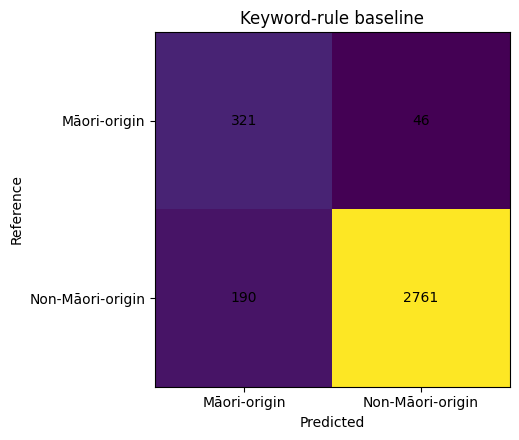

In [21]:
keyword_metrics = metric_row(
    "keyword_rule_baseline",
    test_analysis["y"],
    test_analysis["keyword_prediction"],
    p_maori=None,
)

keyword_metrics_df = pd.DataFrame([keyword_metrics])
display(keyword_metrics_df.round(4))

show_confusion(
    test_analysis["y"],
    test_analysis["keyword_prediction"],
    "Keyword-rule baseline",
    "confusion_keyword_rule_baseline.png",
)

keyword_metrics_df.to_csv(OUTPUT_DIR / "keyword_rule_metrics.csv", index=False)
test_analysis[[c for c in [ID_COL, "title", "reference_label", "keyword_prediction", "keyword_match_count", "keyword_matched_terms", "keyword_matched_categories", "broad_overlap_terms"] if c in test_analysis.columns]].to_csv(
    OUTPUT_DIR / "keyword_rule_test_predictions.csv", index=False
)

## 8. Lexicon coverage audit

This is not model fitting. It measures how often the predefined lexical triggers appear in each reference class. It is useful for testing the claim that Māori-associated vocabulary can occur in both classes.

In [22]:
coverage_table = pd.crosstab(
    test_analysis["reference_label"],
    test_analysis["has_keyword_trigger"],
    rownames=["reference_label"],
    colnames=["contains_predefined_maori_trigger"],
    margins=True,
)
display(coverage_table)
coverage_table.to_csv(OUTPUT_DIR / "keyword_trigger_coverage_test.csv")

# Per-term prevalence is computed on TRAINING data so it can be interpreted
# without mining the held-out test set for new rules.
flat_terms = sorted(set(term for terms in MAORI_LEXICON.values() for term in terms))

# Optimize: Normalize lexical_text once
train_analysis_normalized_text = train_analysis["lexical_text"].map(normalize_for_rules)

# Optimize: Pre-compile regex patterns for all terms
compiled_patterns = {}
for term in flat_terms:
    normalized_term = normalize_for_rules(term)
    pattern_str = r"(?<!\\w)" + re.escape(normalized_term).replace(r"\\ ", r"\\s+") + r"(?!\\w)"
    compiled_patterns[term] = re.compile(pattern_str)

# Optimize: Generate boolean DataFrame of matches using vectorized str.contains
match_series_list = []
for term, compiled_pattern in compiled_patterns.items():
    match_series = train_analysis_normalized_text.str.contains(compiled_pattern, regex=True)
    match_series.name = term  # Name the series after the term
    match_series_list.append(match_series)

term_matches_df = pd.concat(match_series_list, axis=1)

# Get masks once
maori_mask = train_analysis["y"].eq(1)
non_mask = train_analysis["y"].eq(0)

# Optimize: Calculate statistics using vectorized operations
term_data = {
    "term": term_matches_df.columns.to_list(),
    "train_docs_total": term_matches_df.sum(axis=0).values,
    "train_maori_docs": term_matches_df[maori_mask].sum(axis=0).values,
    "train_non_maori_docs": term_matches_df[non_mask].sum(axis=0).values,
    "train_maori_prevalence": term_matches_df[maori_mask].mean(axis=0).values,
    "train_non_maori_prevalence": term_matches_df[non_mask].mean(axis=0).values,
}

lexicon_prevalence_df = pd.DataFrame(term_data).sort_values(
    ["train_maori_prevalence", "train_docs_total"], ascending=False
)
lexicon_prevalence_df.to_csv(OUTPUT_DIR / "lexicon_term_prevalence_training.csv", index=False)
display(lexicon_prevalence_df.head(30).round(4))

contains_predefined_maori_trigger,False,True,All
reference_label,,,
maori_origin,46,321,367
non_maori_origin,2761,190,2951
All,2807,511,3318


,term,train_docs_total,train_maori_docs,train_non_maori_docs,train_maori_prevalence,train_non_maori_prevalence
8,maori,1262,1169,93,0.7958,0.0079
59,whanau,265,237,28,0.1613,0.0024
55,waikato,813,208,605,0.1416,0.0513
5,kaupapa maori,195,195,0,0.1327,0.0000
1,iwi,247,181,66,0.1232,0.0056
45,te reo,152,148,4,0.1007,0.0003
48,tikanga,131,131,0,0.0892,0.0000
46,te reo maori,130,127,3,0.0865,0.0003
39,matauranga,112,112,0,0.0762,0.0000
0,hapu,108,106,2,0.0722,0.0002


In [24]:
display(coverage_table[False].to_frame())

,False
reference_label,
maori_origin,46
non_maori_origin,2761
All,2807


# Part B — Controlled TF-IDF + Logistic Regression experiments

## 9. Pre-specified 2×2 ablation

Only **two factors** are varied:

1. lexical representation: unigram only vs unigram + phrase features (1–3 grams),
2. class weighting: none vs `balanced`.

All other settings are held constant. This allows separate interpretation of phrase representation and class weighting.

The phrase condition uses up to trigrams so phrases such as `te reo` and `treaty of waitangi` can be represented directly.

In [25]:
TFIDF_CONFIGS = {
    "unigram_unweighted": {
        "ngram_range": (1, 1),
        "class_weight": None,
    },
    "phrases_1to3_unweighted": {
        "ngram_range": (1, 3),
        "class_weight": None,
    },
    "unigram_balanced": {
        "ngram_range": (1, 1),
        "class_weight": "balanced",
    },
    "phrases_1to3_balanced": {
        "ngram_range": (1, 3),
        "class_weight": "balanced",
    },
}


def make_vectorizer(ngram_range):
    return TfidfVectorizer(
        lowercase=True,
        max_features=MAX_FEATURES,
        min_df=MIN_DF,
        ngram_range=ngram_range,
        norm="l2",
        sublinear_tf=False,
        strip_accents=None,
        token_pattern=r"(?u)\b\w\w+\b",
    )


def make_classifier(class_weight):
    return LogisticRegression(
        C=LR_C,
        solver=LR_SOLVER,
        max_iter=LR_MAX_ITER,
        class_weight=class_weight,
        random_state=SEED,
    )

X_train_text = train_analysis["lexical_text"].fillna("").astype(str)
X_test_text = test_analysis["lexical_text"].fillna("").astype(str)
y_train = train_analysis["y"].to_numpy(dtype=int)
y_test = test_analysis["y"].to_numpy(dtype=int)

model_store = {}
metric_rows = []

for name, cfg in TFIDF_CONFIGS.items():
    print(f"\n=== {name} ===")
    vectorizer = make_vectorizer(cfg["ngram_range"])
    Xtr = vectorizer.fit_transform(X_train_text)
    Xte = vectorizer.transform(X_test_text)

    classifier = make_classifier(cfg["class_weight"])
    classifier.fit(Xtr, y_train)

    pred = classifier.predict(Xte)
    p_maori = classifier.predict_proba(Xte)[:, 1]
    decision = classifier.decision_function(Xte)

    metrics = metric_row(name, y_test, pred, p_maori)
    metric_rows.append(metrics)

    model_store[name] = {
        "config": cfg,
        "vectorizer": vectorizer,
        "classifier": classifier,
        "X_train": Xtr,
        "X_test": Xte,
        "pred": pred,
        "p_maori": p_maori,
        "decision": decision,
    }

ablation_metrics = pd.DataFrame(metric_rows)
display(ablation_metrics.round(4))
ablation_metrics.to_csv(OUTPUT_DIR / "tfidf_ablation_metrics.csv", index=False)


=== unigram_unweighted ===

=== phrases_1to3_unweighted ===

=== unigram_balanced ===

=== phrases_1to3_balanced ===


,model,accuracy,macro_f1,maori_precision,maori_recall,maori_f1,auprc,predicted_maori,tp,fn,fp,tn
0,unigram_unweighted,0.9596,0.8790,0.9794,0.6485,0.7803,0.9263,243,238,129,5,2946
1,phrases_1to3_unweighted,0.9557,0.8655,0.9701,0.6185,0.7554,0.9142,234,227,140,7,2944
2,unigram_balanced,0.9668,0.9169,0.8391,0.8665,0.8525,0.9283,379,318,49,61,2890
3,phrases_1to3_balanced,0.9623,0.9068,0.8103,0.8610,0.8349,0.9148,390,316,51,74,2877


## 10. Traditional-method summary table

In [26]:
traditional_summary = pd.concat(
    [keyword_metrics_df, ablation_metrics],
    ignore_index=True,
)

display(traditional_summary.round(4))
traditional_summary.to_csv(OUTPUT_DIR / "traditional_model_summary.csv", index=False)

,model,accuracy,macro_f1,maori_precision,maori_recall,maori_f1,auprc,predicted_maori,tp,fn,fp,tn
0,keyword_rule_baseline,0.9289,0.8451,0.6282,0.8747,0.7312,NaN,511,321,46,190,2761
1,unigram_unweighted,0.9596,0.8790,0.9794,0.6485,0.7803,0.9263,243,238,129,5,2946
2,phrases_1to3_unweighted,0.9557,0.8655,0.9701,0.6185,0.7554,0.9142,234,227,140,7,2944
3,unigram_balanced,0.9668,0.9169,0.8391,0.8665,0.8525,0.9283,379,318,49,61,2890
4,phrases_1to3_balanced,0.9623,0.9068,0.8103,0.8610,0.8349,0.9148,390,316,51,74,2877


## 11. Precision–recall curves for the four TF-IDF configurations

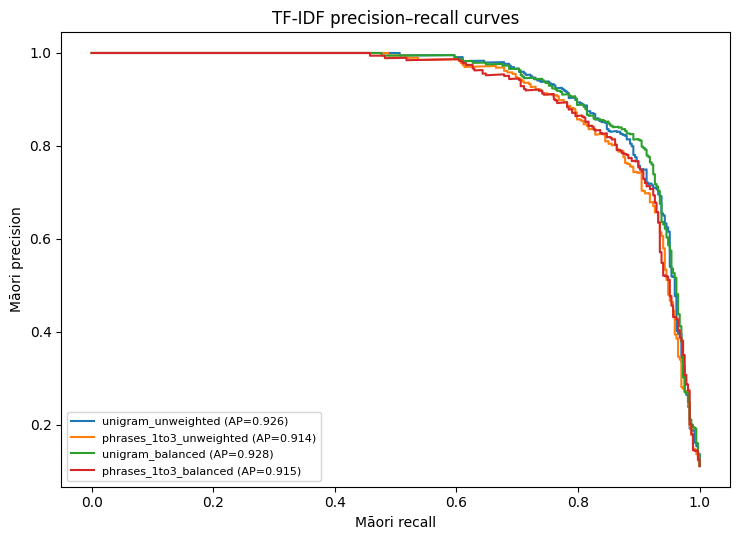

In [27]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for name, obj in model_store.items():
    precision, recall, _ = precision_recall_curve(y_test, obj["p_maori"])
    ap = average_precision_score(y_test, obj["p_maori"])
    ax.plot(recall, precision, label=f"{name} (AP={ap:.3f})")

ax.set_xlabel("Māori recall")
ax.set_ylabel("Māori precision")
ax.set_title("TF-IDF precision–recall curves")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "tfidf_precision_recall_curves.png", dpi=200, bbox_inches="tight")
plt.show()

## 12. Confusion matrices for all controlled TF-IDF configurations

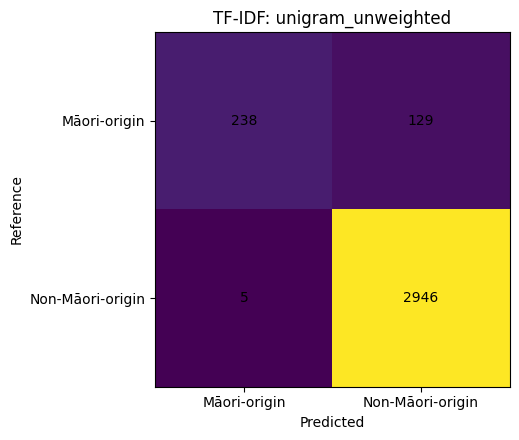

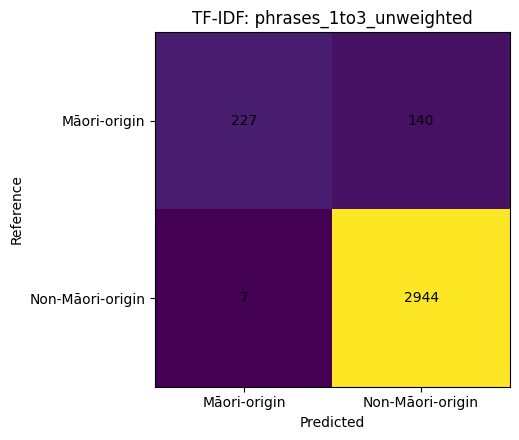

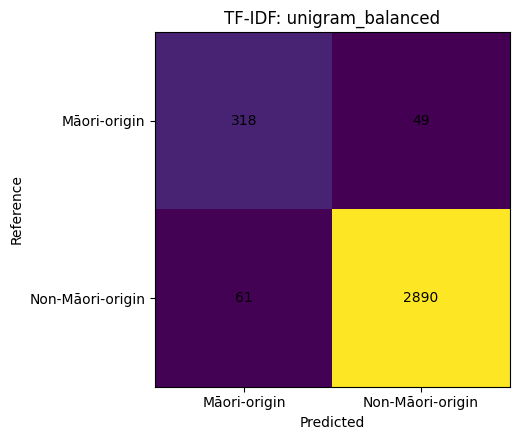

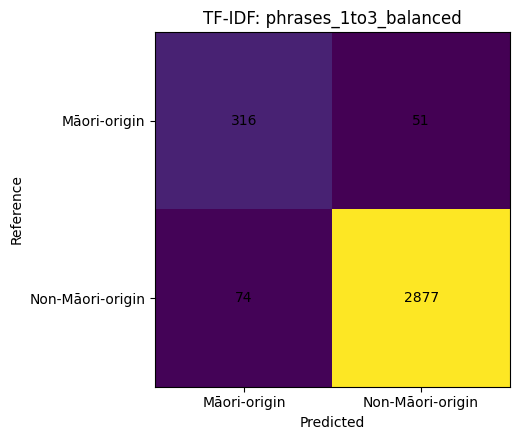

In [28]:
for name, obj in model_store.items():
    show_confusion(
        y_test,
        obj["pred"],
        f"TF-IDF: {name}",
        f"confusion_{name}.png",
    )

# Part C — Statistical uncertainty for the held-out results

## 13. Stratified bootstrap 95% confidence intervals

The bootstrap resamples Māori-origin and non-Māori-origin test records separately so the natural class counts remain fixed in each replicate. This quantifies uncertainty around held-out metrics; it does not change model predictions.

In [29]:
def stratified_bootstrap_indices(y, rng):
    y = np.asarray(y)
    idx_pos = np.where(y == 1)[0]
    idx_neg = np.where(y == 0)[0]
    sample_pos = rng.choice(idx_pos, size=len(idx_pos), replace=True)
    sample_neg = rng.choice(idx_neg, size=len(idx_neg), replace=True)
    idx = np.concatenate([sample_pos, sample_neg])
    rng.shuffle(idx)
    return idx


def metrics_for_bootstrap(y_true, y_pred, p_maori=None):
    result = {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "maori_precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "maori_recall": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "maori_f1": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
    }
    if p_maori is not None:
        result["auprc"] = average_precision_score(y_true, p_maori)
    return result


def bootstrap_ci(name, y_true, y_pred, p_maori=None, n_boot=BOOTSTRAP_N, seed=SEED):
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    p_maori = None if p_maori is None else np.asarray(p_maori)

    values = {}
    point = metrics_for_bootstrap(y_true, y_pred, p_maori)
    for metric in point:
        values[metric] = []

    for _ in range(n_boot):
        idx = stratified_bootstrap_indices(y_true, rng)
        boot = metrics_for_bootstrap(
            y_true[idx],
            y_pred[idx],
            None if p_maori is None else p_maori[idx],
        )
        for metric, value in boot.items():
            values[metric].append(value)

    rows = []
    for metric, vals in values.items():
        vals = np.asarray(vals)
        rows.append({
            "model": name,
            "metric": metric,
            "estimate": point[metric],
            "ci_lower_95": np.quantile(vals, 0.025),
            "ci_upper_95": np.quantile(vals, 0.975),
            "bootstrap_n": n_boot,
        })
    return rows

ci_rows = []
ci_rows += bootstrap_ci(
    "keyword_rule_baseline",
    y_test,
    test_analysis["keyword_prediction"].to_numpy(),
    p_maori=None,
)
for name, obj in model_store.items():
    ci_rows += bootstrap_ci(name, y_test, obj["pred"], obj["p_maori"])

bootstrap_ci_df = pd.DataFrame(ci_rows)
bootstrap_ci_df.to_csv(OUTPUT_DIR / "bootstrap_95ci_metrics.csv", index=False)
display(bootstrap_ci_df.round(4))

,model,metric,estimate,ci_lower_95,ci_upper_95,bootstrap_n
0,keyword_rule_baseline,accuracy,0.9289,0.9201,0.9376,2000
1,keyword_rule_baseline,macro_f1,0.8451,0.8287,0.8619,2000
2,keyword_rule_baseline,maori_precision,0.6282,0.5960,0.6620,2000
3,keyword_rule_baseline,maori_recall,0.8747,0.8419,0.9074,2000
4,keyword_rule_baseline,maori_f1,0.7312,0.7034,0.7598,2000
5,unigram_unweighted,accuracy,0.9596,0.9545,0.9650,2000
6,unigram_unweighted,macro_f1,0.8790,0.8605,0.8983,2000
7,unigram_unweighted,maori_precision,0.9794,0.9605,0.9957,2000
8,unigram_unweighted,maori_recall,0.6485,0.6022,0.6975,2000
9,unigram_unweighted,maori_f1,0.7803,0.7458,0.8159,2000


## 14. Paired bootstrap differences for the ablations

Because the same held-out records are evaluated by every configuration, paired bootstrap differences are more informative than comparing rounded point estimates alone.

Planned contrasts:

- phrase effect without weighting: `phrases_1to3_unweighted − unigram_unweighted`
- class-weight effect for unigrams: `unigram_balanced − unigram_unweighted`
- class-weight effect with phrases: `phrases_1to3_balanced − phrases_1to3_unweighted`
- phrase effect under class weighting: `phrases_1to3_balanced − unigram_balanced`

In [30]:
PAIRED_CONTRASTS = [
    ("phrase_effect_unweighted", "phrases_1to3_unweighted", "unigram_unweighted"),
    ("weight_effect_unigram", "unigram_balanced", "unigram_unweighted"),
    ("weight_effect_phrases", "phrases_1to3_balanced", "phrases_1to3_unweighted"),
    ("phrase_effect_balanced", "phrases_1to3_balanced", "unigram_balanced"),
]


def paired_bootstrap_difference(contrast_name, model_a_name, model_b_name, n_boot=BOOTSTRAP_N, seed=SEED):
    rng = np.random.default_rng(seed)
    a = model_store[model_a_name]
    b = model_store[model_b_name]

    point_a = metrics_for_bootstrap(y_test, a["pred"], a["p_maori"])
    point_b = metrics_for_bootstrap(y_test, b["pred"], b["p_maori"])
    metrics = sorted(set(point_a).intersection(point_b))

    diffs = {metric: [] for metric in metrics}
    for _ in range(n_boot):
        idx = stratified_bootstrap_indices(y_test, rng)
        ma = metrics_for_bootstrap(y_test[idx], a["pred"][idx], a["p_maori"][idx])
        mb = metrics_for_bootstrap(y_test[idx], b["pred"][idx], b["p_maori"][idx])
        for metric in metrics:
            diffs[metric].append(ma[metric] - mb[metric])

    rows = []
    for metric in metrics:
        vals = np.asarray(diffs[metric])
        rows.append({
            "contrast": contrast_name,
            "model_a": model_a_name,
            "model_b": model_b_name,
            "metric": metric,
            "difference_a_minus_b": point_a[metric] - point_b[metric],
            "ci_lower_95": np.quantile(vals, 0.025),
            "ci_upper_95": np.quantile(vals, 0.975),
            "bootstrap_n": n_boot,
        })
    return rows

paired_rows = []
for contrast_name, a, b in PAIRED_CONTRASTS:
    paired_rows += paired_bootstrap_difference(contrast_name, a, b)

paired_bootstrap_df = pd.DataFrame(paired_rows)
paired_bootstrap_df.to_csv(OUTPUT_DIR / "paired_bootstrap_ablation_differences.csv", index=False)
display(paired_bootstrap_df.round(4))

,contrast,model_a,model_b,metric,difference_a_minus_b,ci_lower_95,ci_upper_95,bootstrap_n
0,phrase_effect_unweighted,phrases_1to3_unweighted,unigram_unweighted,accuracy,-0.0039,-0.0066,-0.0015,2000
1,phrase_effect_unweighted,phrases_1to3_unweighted,unigram_unweighted,auprc,-0.0121,-0.0169,-0.0076,2000
2,phrase_effect_unweighted,phrases_1to3_unweighted,unigram_unweighted,macro_f1,-0.0135,-0.0231,-0.0050,2000
3,phrase_effect_unweighted,phrases_1to3_unweighted,unigram_unweighted,maori_f1,-0.0249,-0.0426,-0.0093,2000
4,phrase_effect_unweighted,phrases_1to3_unweighted,unigram_unweighted,maori_precision,-0.0093,-0.0225,-0.0005,2000
5,phrase_effect_unweighted,phrases_1to3_unweighted,unigram_unweighted,maori_recall,-0.0300,-0.0518,-0.0082,2000
6,weight_effect_unigram,unigram_balanced,unigram_unweighted,accuracy,0.0072,0.0006,0.0136,2000
7,weight_effect_unigram,unigram_balanced,unigram_unweighted,auprc,0.0020,-0.0014,0.0054,2000
8,weight_effect_unigram,unigram_balanced,unigram_unweighted,macro_f1,0.0379,0.0189,0.0561,2000
9,weight_effect_unigram,unigram_balanced,unigram_unweighted,maori_f1,0.0722,0.0376,0.1051,2000


# Part D — Probability calibration for the pre-specified final TF-IDF model

## 15. Fit a training-only calibrated companion model

`predict_proba()` from logistic regression is a model probability, not automatically a trustworthy statement of certainty. This section therefore fits a sigmoid-calibrated companion model using **5-fold cross-validation entirely within the training split**.

The calibrated probability is used for probability reliability analysis and per-record reporting. The original linear model remains the source of feature coefficients and exact local feature contributions.

In [31]:
final_cfg = TFIDF_CONFIGS[FINAL_CONFIG_NAME]

base_pipeline = Pipeline([
    ("tfidf", make_vectorizer(final_cfg["ngram_range"])),
    ("lr", make_classifier(final_cfg["class_weight"])),
])

# sklearn changed the parameter name from base_estimator -> estimator.
try:
    calibrated_model = CalibratedClassifierCV(
        estimator=base_pipeline,
        method="sigmoid",
        cv=5,
        n_jobs=-1,
    )
except TypeError:
    calibrated_model = CalibratedClassifierCV(
        base_estimator=base_pipeline,
        method="sigmoid",
        cv=5,
        n_jobs=-1,
    )

calibrated_model.fit(X_train_text, y_train)
p_maori_calibrated = calibrated_model.predict_proba(X_test_text)[:, 1]

brier = brier_score_loss(y_test, p_maori_calibrated)
print("Brier score (calibrated final model):", round(brier, 6))

Brier score (calibrated final model): 0.026619


## 16. Reliability diagram and expected calibration error

Expected calibration error (10 bins): 0.009766


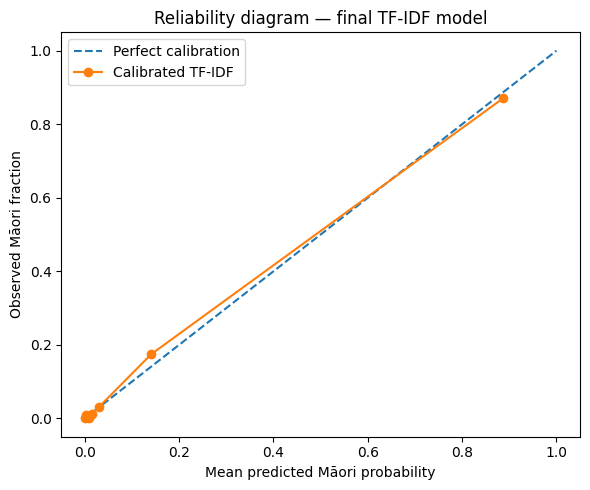

,model,calibration_method,brier_score,ece_10_bins
0,phrases_1to3_balanced,sigmoid_5fold_training_only,0.026619,0.009766


In [32]:
def expected_calibration_error(y_true, probs, n_bins=10):
    y_true = np.asarray(y_true)
    probs = np.asarray(probs)
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    bin_ids = np.digitize(probs, bins[1:-1], right=False)
    ece = 0.0
    rows = []
    for b in range(n_bins):
        mask = bin_ids == b
        if not np.any(mask):
            continue
        mean_prob = probs[mask].mean()
        observed = y_true[mask].mean()
        weight = mask.mean()
        ece += weight * abs(mean_prob - observed)
        rows.append({
            "bin": b,
            "n": int(mask.sum()),
            "mean_predicted_probability": mean_prob,
            "observed_maori_fraction": observed,
            "weight": weight,
        })
    return ece, pd.DataFrame(rows)

ECE, calibration_bins_df = expected_calibration_error(y_test, p_maori_calibrated, n_bins=10)
print("Expected calibration error (10 bins):", round(ECE, 6))

prob_true, prob_pred = calibration_curve(y_test, p_maori_calibrated, n_bins=10, strategy="quantile")
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
ax.plot(prob_pred, prob_true, marker="o", label="Calibrated TF-IDF")
ax.set_xlabel("Mean predicted Māori probability")
ax.set_ylabel("Observed Māori fraction")
ax.set_title("Reliability diagram — final TF-IDF model")
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "calibration_reliability_diagram.png", dpi=200, bbox_inches="tight")
plt.show()

calibration_bins_df.to_csv(OUTPUT_DIR / "calibration_bins.csv", index=False)

calibration_summary = pd.DataFrame([{
    "model": FINAL_CONFIG_NAME,
    "calibration_method": "sigmoid_5fold_training_only",
    "brier_score": brier,
    "ece_10_bins": ECE,
}])
calibration_summary.to_csv(OUTPUT_DIR / "calibration_summary.csv", index=False)
display(calibration_summary.round(6))

# Part E — What did the final TF-IDF model learn?

## 17. Global logistic-regression coefficients and training prevalence

Because `y=1` is Māori-origin:

- positive coefficient → pushes toward Māori-origin
- negative coefficient → pushes toward non-Māori-origin

The coefficient is not a cultural definition of Māori research. It is a learned association with the training reference labels.

In [33]:
final_obj = model_store[FINAL_CONFIG_NAME]
final_vectorizer = final_obj["vectorizer"]
final_classifier = final_obj["classifier"]
final_X_train = final_obj["X_train"]
final_X_test = final_obj["X_test"]

features = final_vectorizer.get_feature_names_out()
coef = final_classifier.coef_[0]

train_maori_mask = y_train == 1
train_non_mask = y_train == 0

df_maori = np.asarray(final_X_train[train_maori_mask].getnnz(axis=0)).ravel()
df_non = np.asarray(final_X_train[train_non_mask].getnnz(axis=0)).ravel()

global_features_df = pd.DataFrame({
    "feature": features,
    "coefficient": coef,
    "direction": np.where(coef > 0, "toward_maori", "toward_non_maori"),
    "feature_type": ["unigram" if " " not in f else f"{len(f.split())}-gram" for f in features],
    "train_doc_frequency": df_maori + df_non,
    "train_maori_doc_frequency": df_maori,
    "train_non_maori_doc_frequency": df_non,
    "train_maori_prevalence": df_maori / train_maori_mask.sum(),
    "train_non_maori_prevalence": df_non / train_non_mask.sum(),
})

global_features_df["prevalence_difference_maori_minus_non"] = (
    global_features_df["train_maori_prevalence"] - global_features_df["train_non_maori_prevalence"]
)

global_features_df.to_csv(OUTPUT_DIR / "tfidf_global_feature_coefficients.csv", index=False)

top_maori_features = global_features_df.sort_values("coefficient", ascending=False).head(30)
top_non_features = global_features_df.sort_values("coefficient", ascending=True).head(30)

top_maori_features.to_csv(OUTPUT_DIR / "tfidf_top_30_maori_direction_features.csv", index=False)
top_non_features.to_csv(OUTPUT_DIR / "tfidf_top_30_non_maori_direction_features.csv", index=False)

print("Top Māori-direction features")
display(top_maori_features.round(4))
print("Top non-Māori-direction features")
display(top_non_features.round(4))

Top Māori-direction features


,feature,coefficient,direction,feature_type,train_doc_frequency,train_maori_doc_frequency,train_non_maori_doc_frequency,train_maori_prevalence,train_non_maori_prevalence,prevalence_difference_maori_minus_non
5271,māori,17.8702,toward_maori,unigram,976,919,57,0.6256,0.0048,0.6208
4938,maori,12.5025,toward_maori,unigram,434,400,34,0.2723,0.0029,0.2694
7879,te,8.1131,toward_maori,unigram,839,600,239,0.4084,0.0203,0.3882
4158,indigenous,7.8284,toward_maori,unigram,652,429,223,0.2920,0.0189,0.2731
4539,iwi,4.4151,toward_maori,unigram,166,164,2,0.1116,0.0002,0.1115
796,aotearoa,4.2078,toward_maori,unigram,811,393,418,0.2675,0.0354,0.2321
2128,cultural,4.0806,toward_maori,unigram,1133,421,712,0.2866,0.0603,0.2263
5272,māori and,3.3050,toward_maori,2-gram,312,294,18,0.2001,0.0015,0.1986
9825,whānau,3.0755,toward_maori,unigram,206,185,21,0.1259,0.0018,0.1242
4943,marae,3.0738,toward_maori,unigram,66,66,0,0.0449,0.0000,0.0449


Top non-Māori-direction features


,feature,coefficient,direction,feature_type,train_doc_frequency,train_maori_doc_frequency,train_non_maori_doc_frequency,train_maori_prevalence,train_non_maori_prevalence,prevalence_difference_maori_minus_non
9429,using,-2.0451,toward_non_maori,unigram,3848,222,3626,0.1511,0.3072,-0.1561
7891,teachers,-1.8380,toward_non_maori,unigram,893,100,793,0.0681,0.0672,0.0009
4308,international,-1.4754,toward_non_maori,unigram,793,79,714,0.0538,0.0605,-0.0067
7395,small,-1.4536,toward_non_maori,unigram,1162,54,1108,0.0368,0.0939,-0.0571
1592,chinese,-1.3575,toward_non_maori,unigram,166,3,163,0.0020,0.0138,-0.0118
2071,countries,-1.3273,toward_non_maori,unigram,543,25,518,0.0170,0.0439,-0.0269
7914,technology,-1.3152,toward_non_maori,unigram,1022,71,951,0.0483,0.0806,-0.0322
1282,between,-1.3072,toward_non_maori,unigram,4222,383,3839,0.2607,0.3253,-0.0646
7657,studies,-1.2484,toward_non_maori,unigram,1858,137,1721,0.0933,0.1458,-0.0526
7667,study,-1.2332,toward_non_maori,unigram,4496,423,4073,0.2880,0.3451,-0.0572


## 18. Plot strongest learned coefficients

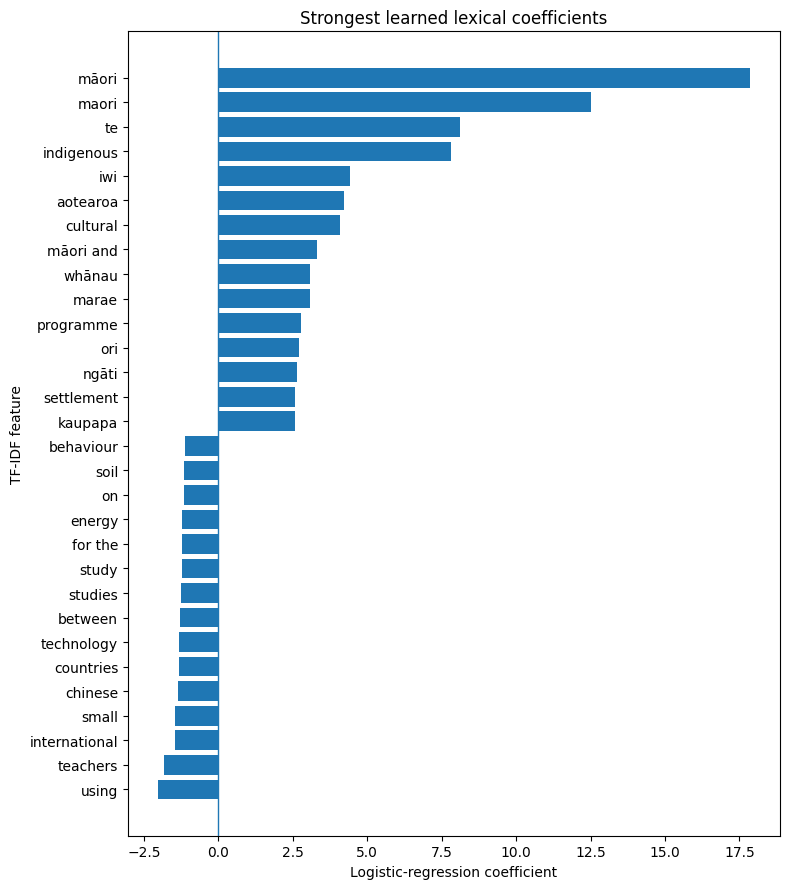

In [34]:
plot_n = 15
plot_df = pd.concat([
    global_features_df.nsmallest(plot_n, "coefficient"),
    global_features_df.nlargest(plot_n, "coefficient"),
]).sort_values("coefficient")

fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(plot_df["feature"], plot_df["coefficient"])
ax.axvline(0, linewidth=1)
ax.set_xlabel("Logistic-regression coefficient")
ax.set_ylabel("TF-IDF feature")
ax.set_title("Strongest learned lexical coefficients")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "tfidf_top_coefficients.png", dpi=200, bbox_inches="tight")
plt.show()

# Part F — Exact per-record TF-IDF explanations

## 19. Compute local feature contributions

For a linear logistic-regression classifier, each active TF-IDF feature contributes:

\[
\text{contribution}_j = x_j \beta_j
\]

and the full decision score is:

\[
b + \sum_j x_j\beta_j.
\]

This is the model's actual linear arithmetic, not an LLM-style narrative reason and not a post-hoc approximation.

In [35]:
def explain_sparse_row(X_row, feature_names, coefficients, top_k=8):
    indices = X_row.indices
    values = X_row.data
    if len(indices) == 0:
        return [], []

    contributions = values * coefficients[indices]
    rows = [
        {
            "feature": str(feature_names[idx]),
            "tfidf": float(val),
            "coefficient": float(coefficients[idx]),
            "contribution": float(contrib),
        }
        for idx, val, contrib in zip(indices, values, contributions)
    ]

    positive = sorted(
        [r for r in rows if r["contribution"] > 0],
        key=lambda r: r["contribution"],
        reverse=True,
    )[:top_k]
    negative = sorted(
        [r for r in rows if r["contribution"] < 0],
        key=lambda r: r["contribution"],
    )[:top_k]
    return positive, negative

final_pred = final_obj["pred"]
final_p_raw = final_obj["p_maori"]
final_decision = final_obj["decision"]

output_df = test_analysis.copy()
output_df["tfidf_prediction"] = np.where(final_pred == 1, "maori_origin", "non_maori_origin")
output_df["p_maori_raw"] = final_p_raw
output_df["p_maori_calibrated"] = p_maori_calibrated
output_df["decision_score"] = final_decision
output_df["decision_margin_abs"] = np.abs(final_decision)
output_df["reference_agreement"] = final_pred == y_test

supporting_json = []
opposing_json = []
for i in range(final_X_test.shape[0]):
    pos, neg = explain_sparse_row(final_X_test[i], features, coef, top_k=8)
    supporting_json.append(json.dumps(pos, ensure_ascii=False))
    opposing_json.append(json.dumps(neg, ensure_ascii=False))

output_df["top_features_toward_maori"] = supporting_json
output_df["top_features_toward_non_maori"] = opposing_json

# Save the complete per-record analysis output.
output_columns = [
    c for c in [
        ID_COL, "title", "subjects", "abstract", "reference_label",
        "tfidf_prediction", "p_maori_raw", "p_maori_calibrated",
        "decision_score", "decision_margin_abs", "reference_agreement",
        "keyword_match_count", "keyword_matched_terms", "keyword_matched_categories",
        "broad_overlap_terms", "top_features_toward_maori", "top_features_toward_non_maori",
    ] if c in output_df.columns
]

output_df[output_columns].to_csv(OUTPUT_DIR / "tfidf_final_per_record_test_output.csv", index=False)
print("Saved per-record output:", OUTPUT_DIR / "tfidf_final_per_record_test_output.csv")
display(output_df[output_columns].head(5))

Saved per-record output: /content/tfidf_traditional_outputs/tfidf_final_per_record_test_output.csv


,record_id_hash,title,subjects,abstract,reference_label,tfidf_prediction,p_maori_raw,p_maori_calibrated,decision_score,decision_margin_abs,reference_agreement,keyword_match_count,keyword_matched_terms,keyword_matched_categories,broad_overlap_terms,top_features_toward_maori,top_features_toward_non_maori
0,f3216214e6f1b0b1b79207699a6584de62328c76eccef4...,Exploring the experiences of female students' ...,Transitions,Educational transitions take place when childr...,non_maori_origin,non_maori_origin,0.099795,0.010096,-2.199499,2.199499,True,0,[],[],"[""education"", ""social"", ""environment"", ""resear...","[{""feature"": ""and"", ""tfidf"": 0.169084446518612...","[{""feature"": ""women"", ""tfidf"": 0.2941735518151..."
1,3453bdd8f4f86774ba2a95c9cbc58e28a48a55eb739ea0...,Distributed Operating Systems on Wireless Sens...,Wireless Sensor Networks,This thesis proposes the use of traditional di...,non_maori_origin,non_maori_origin,0.032597,0.001116,-3.390411,3.390411,True,0,[],[],"[""environment""]","[{""feature"": ""to"", ""tfidf"": 0.0687035564564907...","[{""feature"": ""sensor"", ""tfidf"": 0.579915813326..."
2,a1eb558034276279b926230f75d3d8c3f74dc9c2f977e0...,Learning to link with Wikipedia,computer science,This paper describes a new technique for obtai...,non_maori_origin,non_maori_origin,0.040431,0.001745,-3.166894,3.166894,True,0,[],[],[],"[{""feature"": ""evaluation"", ""tfidf"": 0.09421249...","[{""feature"": ""using"", ""tfidf"": 0.0503744309063..."
3,b2081e367b06428499265f6f9c854d3c5a71f6d73898ba...,The coherence of traumatic and non-traumatic m...,Memory,There is contention in the scientific literatu...,non_maori_origin,non_maori_origin,0.098237,0.008270,-2.216966,2.216966,True,0,[],[],[],"[{""feature"": ""memories"", ""tfidf"": 0.4803133434...","[{""feature"": ""memory"", ""tfidf"": 0.209267196077..."
4,67fa000fc39932995bfda55aedcb77354fd80725b0a78b...,Stimulus Equivalence: A Comparison of Operant ...,Behavioural Psychology,Previous studies comparing the effectiveness o...,non_maori_origin,non_maori_origin,0.053655,0.002825,-2.870036,2.870036,True,0,[],[],[],"[{""feature"": ""to"", ""tfidf"": 0.1353988112940971...","[{""feature"": ""more"", ""tfidf"": 0.09845338871105..."


# Part G — Lexical challenge groups

## 20. Define evaluation-only challenge groups

These groups are created **after prediction** for analysis. They are not used to train or modify the classifier.

- `reference_maori_explicit_trigger`: reference Māori-origin + at least one predefined Māori lexical trigger
- `reference_maori_no_explicit_trigger`: reference Māori-origin + no predefined Māori trigger
- `reference_non_maori_with_maori_trigger`: reference non-Māori-origin + Māori trigger present (potential incidental/overlap condition)
- `reference_non_maori_broad_context_only`: reference non-Māori-origin + no Māori trigger + broad contextual term(s)
- `reference_non_maori_no_selected_signal`: reference non-Māori-origin + neither selected Māori nor broad overlap terms

The labels are used here only to define evaluation strata for comparison.

In [36]:
def assign_challenge_group(row):
    if row["y"] == 1 and row["has_keyword_trigger"]:
        return "reference_maori_explicit_trigger"
    if row["y"] == 1 and not row["has_keyword_trigger"]:
        return "reference_maori_no_explicit_trigger"
    if row["y"] == 0 and row["has_keyword_trigger"]:
        return "reference_non_maori_with_maori_trigger"
    if row["y"] == 0 and (not row["has_keyword_trigger"]) and row["has_broad_overlap"]:
        return "reference_non_maori_broad_context_only"
    return "reference_non_maori_no_selected_signal"

output_df["lexical_challenge_group"] = output_df.apply(assign_challenge_group, axis=1)

challenge_rows = []
for group, g in output_df.groupby("lexical_challenge_group", sort=False):
    idx = g.index.to_numpy()
    y_g = g["y"].to_numpy(dtype=int)
    pred_g = (g["tfidf_prediction"] == "maori_origin").astype(int).to_numpy()
    keyword_g = g["keyword_prediction"].to_numpy(dtype=int)

    challenge_rows.append({
        "group": group,
        "n": len(g),
        "reference_maori_fraction": y_g.mean(),
        "tfidf_agreement_rate": (pred_g == y_g).mean(),
        "tfidf_predicted_maori_rate": pred_g.mean(),
        "keyword_agreement_rate": (keyword_g == y_g).mean(),
        "keyword_predicted_maori_rate": keyword_g.mean(),
        "mean_p_maori_calibrated": g["p_maori_calibrated"].mean(),
        "median_p_maori_calibrated": g["p_maori_calibrated"].median(),
    })

challenge_results_df = pd.DataFrame(challenge_rows)
challenge_results_df.to_csv(OUTPUT_DIR / "lexical_challenge_group_results.csv", index=False)
display(challenge_results_df.round(4))

,group,n,reference_maori_fraction,tfidf_agreement_rate,tfidf_predicted_maori_rate,keyword_agreement_rate,keyword_predicted_maori_rate,mean_p_maori_calibrated,median_p_maori_calibrated
0,reference_non_maori_broad_context_only,1731,0.0,0.9728,0.0272,1.0,0.0,0.0315,0.0080
1,reference_non_maori_no_selected_signal,1030,0.0,0.9981,0.0019,1.0,0.0,0.0070,0.0023
2,reference_maori_explicit_trigger,321,1.0,0.9159,0.9159,1.0,1.0,0.8232,0.9922
3,reference_non_maori_with_maori_trigger,190,0.0,0.8684,0.1316,0.0,1.0,0.1130,0.0255
4,reference_maori_no_explicit_trigger,46,1.0,0.4783,0.4783,0.0,0.0,0.3475,0.2115


## 21. Plot agreement by lexical challenge group

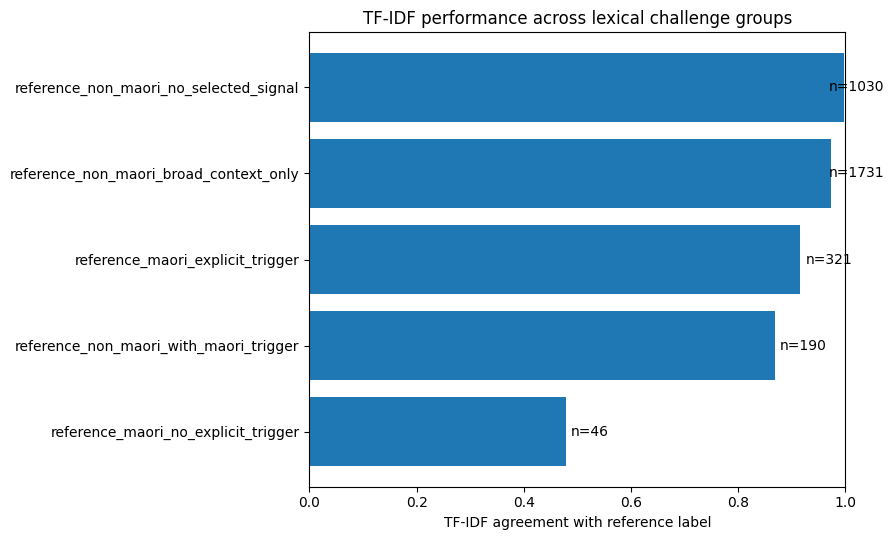

In [37]:
plot_groups = challenge_results_df.sort_values("tfidf_agreement_rate")
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(plot_groups["group"], plot_groups["tfidf_agreement_rate"])
ax.set_xlim(0, 1)
ax.set_xlabel("TF-IDF agreement with reference label")
ax.set_title("TF-IDF performance across lexical challenge groups")
for i, (_, row) in enumerate(plot_groups.iterrows()):
    ax.text(min(row["tfidf_agreement_rate"] + 0.01, 0.97), i, f'n={int(row["n"])}', va="center")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "lexical_challenge_group_agreement.png", dpi=200, bbox_inches="tight")
plt.show()

# Part H — Systematic disagreement analysis

## 22. Separate reference-relative disagreement types

The conventional names false positive / false negative are used only relative to the existing reference labels.

In [38]:
def disagreement_type(row):
    ref = row["y"]
    pred = 1 if row["tfidf_prediction"] == "maori_origin" else 0
    if ref == pred:
        return "agreement"
    if ref == 1 and pred == 0:
        return "reference_maori_predicted_non_maori"
    return "reference_non_maori_predicted_maori"

output_df["disagreement_type"] = output_df.apply(disagreement_type, axis=1)

disagreements_df = output_df[output_df["disagreement_type"] != "agreement"].copy()
disagreements_df = disagreements_df.sort_values("decision_margin_abs", ascending=False)

disagreement_columns = [
    c for c in [
        ID_COL, "title", "subjects", "abstract", "reference_label", "tfidf_prediction",
        "p_maori_raw", "p_maori_calibrated", "decision_score", "decision_margin_abs",
        "disagreement_type", "lexical_challenge_group", "keyword_matched_terms",
        "broad_overlap_terms", "top_features_toward_maori", "top_features_toward_non_maori",
    ] if c in disagreements_df.columns
]

disagreements_df[disagreement_columns].to_csv(OUTPUT_DIR / "tfidf_disagreements.csv", index=False)

print("Total disagreements:", len(disagreements_df))
print(disagreements_df["disagreement_type"].value_counts())
print("\nDisagreements by challenge group:")
print(pd.crosstab(disagreements_df["lexical_challenge_group"], disagreements_df["disagreement_type"]))

Total disagreements: 125
disagreement_type
reference_non_maori_predicted_maori    74
reference_maori_predicted_non_maori    51
Name: count, dtype: int64

Disagreements by challenge group:
disagreement_type                       reference_maori_predicted_non_maori  \
lexical_challenge_group                                                       
reference_maori_explicit_trigger                                         27   
reference_maori_no_explicit_trigger                                      24   
reference_non_maori_broad_context_only                                    0   
reference_non_maori_no_selected_signal                                    0   
reference_non_maori_with_maori_trigger                                    0   

disagreement_type                       reference_non_maori_predicted_maori  
lexical_challenge_group                                                      
reference_maori_explicit_trigger                                          0  
reference_maori_no_expli

## 23. Reproducible representative cases

Rather than hand-picking examples, this cell uses a pre-defined selection rule:

- up to 3 largest-margin disagreements of each type,
- up to 3 closest-to-boundary disagreements of each type.

This produces a small audit set without choosing cases because they tell a preferred story.

In [39]:
case_frames = []
for dtype, g in disagreements_df.groupby("disagreement_type"):
    high_margin = g.nlargest(3, "decision_margin_abs").copy()
    high_margin["case_selection"] = "largest_decision_margin"

    near_boundary = g.nsmallest(3, "decision_margin_abs").copy()
    near_boundary["case_selection"] = "closest_to_boundary"

    case_frames.extend([high_margin, near_boundary])

representative_cases_df = pd.concat(case_frames, ignore_index=True) if case_frames else pd.DataFrame()

if len(representative_cases_df):
    rep_cols = ["case_selection"] + disagreement_columns
    representative_cases_df[rep_cols].to_csv(OUTPUT_DIR / "tfidf_representative_cases.csv", index=False)
    display(representative_cases_df[rep_cols])
else:
    print("No disagreement cases found.")

,case_selection,record_id_hash,title,subjects,abstract,reference_label,tfidf_prediction,p_maori_raw,p_maori_calibrated,decision_score,decision_margin_abs,disagreement_type,lexical_challenge_group,keyword_matched_terms,broad_overlap_terms,top_features_toward_maori,top_features_toward_non_maori
0,largest_decision_margin,66dd8571d1ff45559891051c4d3525491499831ca039f4...,"Perceptions, expectations and interactions: a ...",None,"Teachers’ perceptions of their pupils, expecta...",maori_origin,non_maori_origin,0.036470,0.001692,-3.274123,3.274123,reference_maori_predicted_non_maori,reference_maori_no_explicit_trigger,[],"[""new zealand"", ""education"", ""social"", ""resear...","[{""feature"": ""and"", ""tfidf"": 0.156976559667339...","[{""feature"": ""teachers"", ""tfidf"": 0.1951794378..."
1,largest_decision_margin,435eb7257039b6448b16b9e8b1b4f6d96f14af838ec109...,In vitro cell culture to study microglial infl...,CNs,Inflammation of the central nervous system (CN...,maori_origin,non_maori_origin,0.048021,0.002090,-2.986895,2.986895,reference_maori_predicted_non_maori,reference_maori_explicit_trigger,"[""maori""]",[],"[{""feature"": ""maori"", ""tfidf"": 0.0225489137488...","[{""feature"": ""cells"", ""tfidf"": 0.4238280864045..."
2,largest_decision_margin,a53ead8f037d7813df267bec29e280cefd14a4c4d37763...,The relationship between on-water performance ...,None,Objectives: The aim of the present study was t...,maori_origin,non_maori_origin,0.048314,0.002328,-2.980524,2.980524,reference_maori_predicted_non_maori,reference_maori_no_explicit_trigger,[],[],"[{""feature"": ""and"", ""tfidf"": 0.148811626117321...","[{""feature"": ""elite"", ""tfidf"": 0.5120385156942..."
3,closest_to_boundary,c3760e7af691d6692a91b107019b227967015be4e03718...,lnteragency collaboration in youth justice: Cr...,None,This thesis describes a community psychology i...,maori_origin,non_maori_origin,0.484703,0.266555,-0.061206,0.061206,reference_maori_predicted_non_maori,reference_maori_explicit_trigger,"[""maori""]","[""community"", ""social"", ""environment"", ""resear...","[{""feature"": ""youth"", ""tfidf"": 0.2648163406931...","[{""feature"": ""sector"", ""tfidf"": 0.119944123641..."
4,closest_to_boundary,b21926b41c845cfb2bd630638444101ac730bf20aa73a5...,Boat electrofishing survey of fish populations...,None,The original purpose of this series of surveys...,maori_origin,non_maori_origin,0.469538,0.206086,-0.121997,0.121997,reference_maori_predicted_non_maori,reference_maori_explicit_trigger,"[""maori"", ""taonga""]","[""research""]","[{""feature"": ""maori"", ""tfidf"": 0.0741048322730...","[{""feature"": ""channel"", ""tfidf"": 0.27391655729..."
5,closest_to_boundary,c343d4fe0de7d5d3ddf4591ca27daa3437a29a7c7de892...,Ghost Town,None,Abstract\r\n\r\nA hometown is a thing full of ...,maori_origin,non_maori_origin,0.469537,0.237715,-0.122001,0.122001,reference_maori_predicted_non_maori,reference_maori_explicit_trigger,"[""maori"", ""waikato""]","[""aotearoa"", ""social""]","[{""feature"": ""māori"", ""tfidf"": 0.0341257443702...","[{""feature"": ""town"", ""tfidf"": 0.18152739913183..."
6,largest_decision_margin,6c1d8df7bfb19482718a6785313e38544661185945255f...,Epidemiology of giant cell arteritis in Waikat...,data analytics,Giant cell arteritis (GCA) is the most common ...,non_maori_origin,maori_origin,0.966760,0.990967,3.370194,3.370194,reference_non_maori_predicted_maori,reference_non_maori_with_maori_trigger,"[""maori"", ""waikato""]","[""aotearoa"", ""new zealand"", ""pacific"", ""health""]","[{""feature"": ""māori"", ""tfidf"": 0.0857764250757...","[{""feature"": ""cell"", ""tfidf"": 0.11779535311160..."
7,largest_decision_margin,d1e2b31517e87cf8c0668b725e7cc7d72189e4ebd62beb...,Indigenous data sovereignty,None,• Indigenous Data Sovereignty (IDS) has emerge...,non_maori_origin,maori_origin,0.959608,0.984873,3.167904,3.167904,reference_non_maori_predicted_maori,reference_non_maori_broad_context_only,[],"[""indigenous""]","[{""feature"": ""indigenous"", ""tfi

# Part I — Save final artifacts and a reproducibility manifest

## 24. Save the pre-specified final linear model, vectorizer, calibrated model, rules, and configuration

In [40]:
joblib.dump(final_vectorizer, OUTPUT_DIR / "tfidf_final_vectorizer.joblib")
joblib.dump(final_classifier, OUTPUT_DIR / "tfidf_final_logistic_regression.joblib")
joblib.dump(calibrated_model, OUTPUT_DIR / "tfidf_final_calibrated_model.joblib")

with open(OUTPUT_DIR / "maori_lexicon_rules.json", "w", encoding="utf-8") as f:
    json.dump({
        "maori_lexicon": MAORI_LEXICON,
        "broad_overlap_terms": BROAD_OVERLAP_TERMS,
    }, f, ensure_ascii=False, indent=2)

manifest = {
    "dataset_id": DATASET_ID,
    "train_rows": int(len(train_analysis)),
    "test_rows": int(len(test_analysis)),
    "train_maori": int(y_train.sum()),
    "train_non_maori": int((1-y_train).sum()),
    "test_maori": int(y_test.sum()),
    "test_non_maori": int((1-y_test).sum()),
    "text_fields": TEXT_FIELDS,
    "label_mapping_for_analysis": {"non_maori_origin": 0, "maori_origin": 1},
    "tfidf_common_parameters": {
        "max_features": MAX_FEATURES,
        "min_df": MIN_DF,
        "lowercase": True,
        "norm": "l2",
        "sublinear_tf": False,
        "strip_accents": None,
    },
    "logistic_regression_common_parameters": {
        "C": LR_C,
        "solver": LR_SOLVER,
        "max_iter": LR_MAX_ITER,
        "random_state": SEED,
    },
    "tfidf_configs": {k: {"ngram_range": list(v["ngram_range"]), "class_weight": v["class_weight"]} for k, v in TFIDF_CONFIGS.items()},
    "pre_specified_final_config": FINAL_CONFIG_NAME,
    "calibration": "sigmoid, 5-fold CV using training split only",
    "bootstrap_replicates": BOOTSTRAP_N,
    "seed": SEED,
    "important_scope_note": "No LLM/embedding predictions, reasons, or confidence fields are used in this notebook. Existing reference labels are used as training targets and held-out evaluation references only.",
}

with open(OUTPUT_DIR / "reproducibility_manifest.json", "w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2, ensure_ascii=False)

print(json.dumps(manifest, indent=2, ensure_ascii=False))

{
  "dataset_id": "dinushiTJ/nz_research_commons_classification",
  "train_rows": 13271,
  "test_rows": 3318,
  "train_maori": 1469,
  "train_non_maori": 11802,
  "test_maori": 367,
  "test_non_maori": 2951,
  "text_fields": [
    "title",
    "subjects",
    "abstract"
  ],
  "label_mapping_for_analysis": {
    "non_maori_origin": 0,
    "maori_origin": 1
  },
  "tfidf_common_parameters": {
    "max_features": 10000,
    "min_df": 2,
    "lowercase": true,
    "norm": "l2",
    "sublinear_tf": false,
    "strip_accents": null
  },
  "logistic_regression_common_parameters": {
    "C": 1.0,
    "solver": "liblinear",
    "max_iter": 2000,
    "random_state": 42
  },
  "tfidf_configs": {
    "unigram_unweighted": {
      "ngram_range": [
        1,
        1
      ],
      "class_weight": null
    },
    "phrases_1to3_unweighted": {
      "ngram_range": [
        1,
        3
      ],
      "class_weight": null
    },
    "unigram_balanced": {
      "ngram_range": [
        1,
        1


## 25. Save the complete final per-record output again with challenge/disagreement fields

In [41]:
final_save_columns = [
    c for c in [
        ID_COL, "title", "subjects", "abstract", "reference_label",
        "tfidf_prediction", "p_maori_raw", "p_maori_calibrated",
        "decision_score", "decision_margin_abs", "reference_agreement",
        "keyword_prediction", "keyword_match_count", "keyword_matched_terms",
        "keyword_matched_categories", "broad_overlap_terms",
        "lexical_challenge_group", "disagreement_type",
        "top_features_toward_maori", "top_features_toward_non_maori",
    ] if c in output_df.columns
]

output_df[final_save_columns].to_csv(
    OUTPUT_DIR / "tfidf_final_per_record_test_output_COMPLETE.csv",
    index=False,
)

print("Saved:", OUTPUT_DIR / "tfidf_final_per_record_test_output_COMPLETE.csv")

Saved: /content/tfidf_traditional_outputs/tfidf_final_per_record_test_output_COMPLETE.csv


## 26. Zip all outputs for download/archive

In [42]:
import shutil

archive_path = shutil.make_archive(
    str(OUTPUT_DIR),
    "zip",
    root_dir=OUTPUT_DIR,
)
print("Created archive:", archive_path)

Created archive: /content/tfidf_traditional_outputs.zip


# Optional — push outputs to Hugging Face

This section is disabled by default. Run it only after you have inspected the results and chosen a repository name.

The pushed dataset would contain **traditional-method outputs only**: reference label, TF-IDF prediction/probability, lexical-rule matches, challenge group, and exact linear feature contributions.

In [44]:
PUSH_TO_HUB = False
OUTPUT_DATASET_REPO = "dinushiTJ/nz_research_commons_tfidf_traditional_analysis"

if PUSH_TO_HUB:
    from huggingface_hub import login
    from getpass import getpass

    token = os.getenv("HF_TOKEN") or getpass("Hugging Face token: ")
    login(token=token)

    hf_output = Dataset.from_pandas(output_df[final_save_columns], preserve_index=False)
    hf_output.push_to_hub(OUTPUT_DATASET_REPO, split="test")
    print("Pushed:", OUTPUT_DATASET_REPO)
else:
    print("PUSH_TO_HUB=False — no upload performed.")

PUSH_TO_HUB=False — no upload performed.


# 27. How to interpret the outputs before writing the paper

Do not decide the conclusion in advance. After running the notebook, inspect these outputs in order:

1. `traditional_model_summary.csv` — keyword baseline vs four controlled TF-IDF configurations.
2. `paired_bootstrap_ablation_differences.csv` — whether phrase features and class weighting produce meaningful changes rather than only small point-estimate differences.
3. `tfidf_global_feature_coefficients.csv` — what the learned lexical model actually associates with each reference class.
4. `keyword_trigger_coverage_test.csv` and `lexicon_term_prevalence_training.csv` — whether Māori-associated terms occur in both classes.
5. `lexical_challenge_group_results.csv` — where lexical methods are strong or weak under pre-defined lexical conditions.
6. `tfidf_final_per_record_test_output_COMPLETE.csv` — every paper's TF-IDF prediction, calibrated Māori probability, decision score, rule matches, and exact feature contributions.
7. `tfidf_disagreements.csv` and `tfidf_representative_cases.csv` — systematic audit of disagreements relative to the reference set.
8. `calibration_summary.csv` and `calibration_reliability_diagram.png` — whether per-record probabilities are reliable enough to discuss as model probabilities.

Only after seeing those results should the TF-IDF methodology/results/discussion in the paper be rewritten.